In [1]:
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from tqdm import tqdm

from dataset import ALL_CLASSES, SpeechCommandsDatasetFactory
from model import MelResNetKWS, SincResNetKWS
from model.head import ClassificationHead
from train import train, validate

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
factory = SpeechCommandsDatasetFactory("train")

train_dataset = factory.train(skip_anomalies=True)
val_dataset = factory.val(skip_anomalies=True)
test_dataset = factory.test(skip_anomalies=True)

In [4]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

In [5]:
def freeze(module: nn.Module):
    module.eval()
    for p in module.parameters():
        p.requires_grad_(False)


def unfreeze(module: nn.Module):
    module.train()
    for p in module.parameters():
        p.requires_grad_(True)

In [6]:
model_a = MelResNetKWS(num_classes=12)
model_b = SincResNetKWS(num_classes=12)

In [25]:
model_a.load_state_dict(torch.load("mel.pt", map_location="cpu")["model_state_dict"])

model_a = model_a.to(DEVICE)
head = model_a.head

In [27]:
model_b = model_b.to(DEVICE)

# copy pretrained head and freeze
model_b.head = copy.deepcopy(head)
freeze(model_b.head)

In [9]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_b.parameters(),
    lr=2e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

In [10]:
# train only backbone
train(
    model_b,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    scheduler,
    DEVICE,
    10,
    "model_b.pt",
);


Epoch 1/10


train loss=1.3575 | train F1=0.5283 | train P=0.5277 | train R=0.5366
val   loss=0.6757 | val   F1=0.7692 | val   P=0.7913 | val   R=0.7747
Saved best model. val F1=0.7692

Epoch 2/10


train loss=0.5299 | train F1=0.8263 | train P=0.8258 | train R=0.8282
val   loss=0.3950 | val   F1=0.8675 | val   P=0.8752 | val   R=0.8698
Saved best model. val F1=0.8675

Epoch 3/10


train loss=0.3910 | train F1=0.8733 | train P=0.8729 | train R=0.8741
val   loss=0.3361 | val   F1=0.8872 | val   P=0.8884 | val   R=0.8876
Saved best model. val F1=0.8872

Epoch 4/10


train loss=0.3042 | train F1=0.9048 | train P=0.9045 | train R=0.9052
val   loss=0.3192 | val   F1=0.8978 | val   P=0.9037 | val   R=0.8975
Saved best model. val F1=0.8978

Epoch 5/10


...

train loss=0.2429 | train F1=0.9245 | train P=0.9244 | train R=0.9248
val   loss=0.2543 | val   F1=0.9185 | val   P=0.9204 | val   R=0.9188
Saved best model. val F1=0.9185

Epoch 7/10


train loss=0.2142 | train F1=0.9324 | train P=0.9324 | train R=0.9326
val   loss=0.2283 | val   F1=0.9278 | val   P=0.9300 | val   R=0.9274
Saved best model. val F1=0.9278

Epoch 8/10


train loss=0.1958 | train F1=0.9372 | train P=0.9372 | train R=0.9373
val   loss=0.2259 | val   F1=0.9297 | val   P=0.9307 | val   R=0.9299
Saved best model. val F1=0.9297

Epoch 9/10


train loss=0.1891 | train F1=0.9414 | train P=0.9413 | train R=0.9415
val   loss=0.2270 | val   F1=0.9241 | val   P=0.9262 | val   R=0.9245

Epoch 10/10


train loss=0.1642 | train F1=0.9481 | train P=0.9481 | train R=0.9482
val   loss=0.2435 | val   F1=0.9228 | val   P=0.9261 | val   R=0.9226


In [28]:
def kd_loss(
    student_logits: torch.Tensor, teacher_logits: torch.Tensor, temperature=2.0
):
    t = temperature
    teacher_probs = F.softmax(teacher_logits.float() / t, dim=-1)
    student_log_probs = F.log_softmax(student_logits.float() / t, dim=-1)

    return F.kl_div(student_log_probs, teacher_probs, reduction="batchmean") * (t * t)

In [29]:
# model a is better so we use it as teacher
teacher = copy.deepcopy(model_a)
freeze(teacher)

In [30]:
a_params = model_a.backbone.parameters()
b_params = model_b.backbone.parameters()
head_params = head.parameters()

optimizer = torch.optim.AdamW(
    [
        {"params": a_params, "lr": 3e-5},
        {"params": b_params, "lr": 3e-5},
        {"params": head.parameters(), "lr": 1e-5},
    ],
    weight_decay=1e-4,
)

In [31]:
lambda_align, lambda_kd = 0.1, 1.0

model_a.train()
model_b.train()
head.train()

history = {
    "loss": [],
    "loss_ce": [],
    "loss_align": [],
    "loss_kd": [],
}

epochs = 10

for epoch in range(1, epochs + 1):
    print(f"\n{'=' * 70}")
    print(f"Epoch " f"{epoch}/{epochs}")

    if epoch <= 5:
        # train only backbone
        unfreeze(model_a)
        unfreeze(model_b)

        # freeze head
        freeze(head)
    else:
        # train whole model
        unfreeze(head)

    running_loss = {
        "loss": 0.0,
        "loss_ce": 0.0,
        "loss_align": 0.0,
        "loss_kd": 0.0,
    }
    count = 0

    pbar = tqdm(train_loader, desc="Train", leave=False)

    for batch in pbar:
        speech = batch["speech"].to(DEVICE, non_blocking=True)
        target = batch["target"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        z_a = model_a.backbone(speech)
        z_b = model_b.backbone(speech)

        logits_a = head(z_a)
        logits_b = head(z_b)

        loss_ce = 0.5 * (
            F.cross_entropy(logits_a, target) + F.cross_entropy(logits_b, target)
        )

        loss_align = F.mse_loss(z_a, z_b)

        teacher_logits = teacher(speech)

        loss_kd = 0.5 * (
            kd_loss(logits_a, teacher_logits) + kd_loss(logits_b, teacher_logits)
        )

        loss = loss_ce + lambda_align * epoch * loss_align + lambda_kd * loss_kd

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            list(a_params) + list(b_params) + list(head_params),
            max_norm=5.0,
        )
        optimizer.step()

        batch_size = speech.shape[0]
        count += batch_size

        running_loss["loss"] += loss.item() * batch_size
        running_loss["loss_ce"] += loss_ce.item() * batch_size
        running_loss["loss_align"] += loss_align.item() * batch_size
        running_loss["loss_kd"] += loss_kd.item() * batch_size

        pbar.set_postfix(
            loss=f"{loss.item():.4f}",
            loss_ce=f"{loss_ce.item():.4f}",
            loss_align=f"{loss_align.item():.4f}",
            loss_kd=f"{loss_kd.item():.4f}",
        )

    loss = running_loss["loss"] / max(count, 1)
    loss_ce = running_loss["loss_ce"] / max(count, 1)
    loss_align = running_loss["loss_align"] / max(count, 1)
    loss_kd = running_loss["loss_kd"] / max(count, 1)

    history["loss"].append(loss)
    history["loss_ce"].append(loss_ce)
    history["loss_align"].append(loss_align)
    history["loss_kd"].append(loss_kd)

    print(
        f"loss={loss:.4f} "
        f"| loss_ce={loss_ce:.4f} "
        f"| loss_align={loss_align:.4f} "
        f"| loss_kd={loss_kd:.4f}"
    )

    if epoch == 5:
        best_state = {
            "model_a_backbone": {
                k: v.detach().cpu().clone() for k, v in model_a.backbone.state_dict().items()
            },
            "model_b_backbone": {
                k: v.detach().cpu().clone() for k, v in model_b.backbone.state_dict().items()
            },
            "head": {k: v.detach().cpu().clone() for k, v in head.state_dict().items()},
        }

        torch.save(best_state, "distillated_5.pt")


Epoch 1/10


loss=0.3482 | loss_ce=0.0920 | loss_align=0.6663 | loss_kd=0.1896

Epoch 2/10


loss=0.2907 | loss_ce=0.0807 | loss_align=0.2332 | loss_kd=0.1634

Epoch 3/10


loss=0.2730 | loss_ce=0.0766 | loss_align=0.1372 | loss_kd=0.1553

Epoch 4/10


loss=0.2590 | loss_ce=0.0733 | loss_align=0.0965 | loss_kd=0.1471

Epoch 5/10


...

loss=0.3085 | loss_ce=0.0725 | loss_align=0.0621 | loss_kd=0.1987

Epoch 7/10


loss=0.2987 | loss_ce=0.0712 | loss_align=0.0524 | loss_kd=0.1909

Epoch 8/10


loss=0.2873 | loss_ce=0.0684 | loss_align=0.0446 | loss_kd=0.1832

Epoch 9/10


loss=0.2864 | loss_ce=0.0680 | loss_align=0.0395 | loss_kd=0.1828

Epoch 10/10


loss=0.2699 | loss_ce=0.0639 | loss_align=0.0341 | loss_kd=0.1719


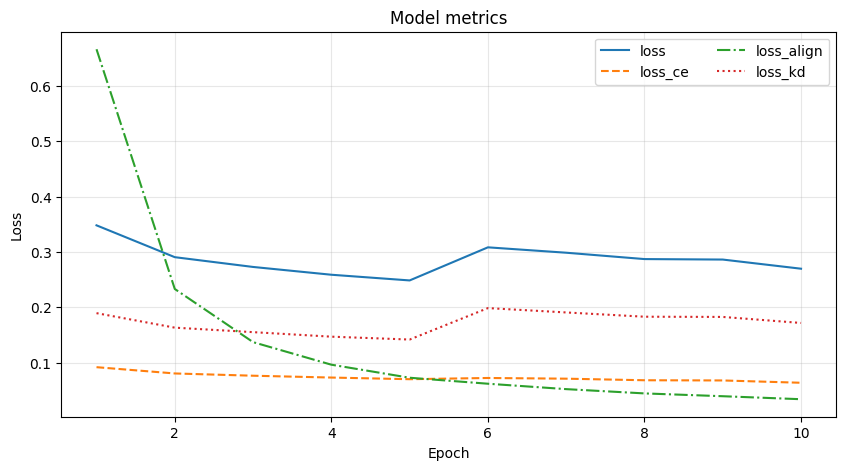

In [32]:
import matplotlib.pyplot as plt

epochs = np.arange(1, len(history["loss"]) + 1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(epochs, history["loss"], label="loss")

ax.plot(
    epochs,
    history["loss_ce"],
    "--",
    label="loss_ce",
)

ax.plot(
    epochs,
    history["loss_align"],
    "-.",
    label="loss_align",
)

ax.plot(
    epochs,
    history["loss_kd"],
    ":",
    label="loss_kd",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Model metrics")

ax.grid(True, alpha=0.3)
ax.legend(ncol=2)

plt.show()

In [33]:
best_state = {
    "model_a_backbone": {
        k: v.detach().cpu().clone() for k, v in model_a.backbone.state_dict().items()
    },
    "model_b_backbone": {
        k: v.detach().cpu().clone() for k, v in model_b.backbone.state_dict().items()
    },
    "head": {k: v.detach().cpu().clone() for k, v in head.state_dict().items()},
}

torch.save(best_state, "distillated.pt")

In [19]:
best_state = torch.load("distillated.pt", map_location="cpu")

head = ClassificationHead(num_classes=12)
model_a.backbone.load_state_dict(best_state["model_a_backbone"])
model_b.backbone.load_state_dict(best_state["model_b_backbone"])
head.load_state_dict(best_state["head"])

model_a.head = copy.deepcopy(head)
model_b.head = copy.deepcopy(head)

model_a = model_a.to(DEVICE)
model_b = model_b.to(DEVICE)

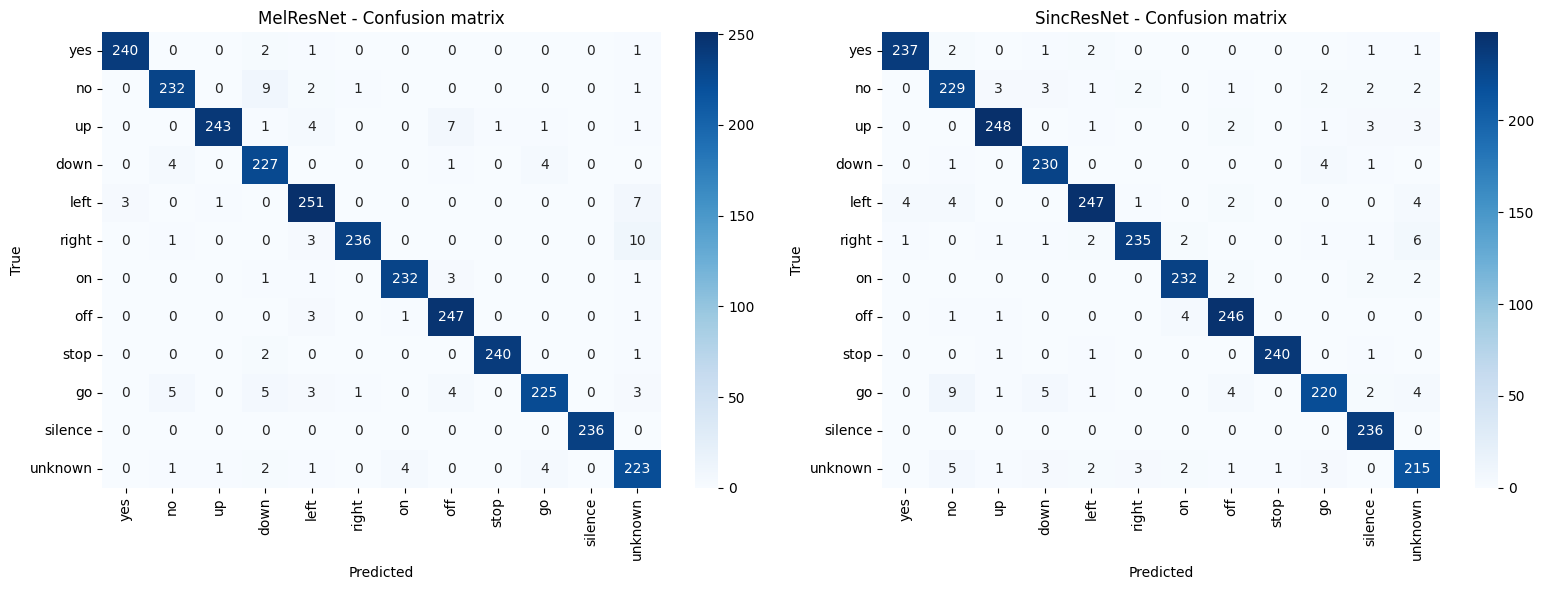

,MelResNet,SincResNet
loss,0.124261,0.167169
accuracy,0.961303,0.955533
precision,0.962098,0.955540
recall,0.961536,0.955711
f1,0.961507,0.955412


In [20]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

_, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

df = pd.DataFrame()

for i, (model_name, model) in enumerate([
    ("MelResNet", model_a),
    ("SincResNet", model_b),
]):
    test_loss, test_metrics, test_true, test_pred = validate(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=DEVICE,
    )

    df.loc[model_name, "loss"] = test_loss
    df.loc[model_name, "accuracy"] = test_metrics["accuracy"]
    df.loc[model_name, "precision"] = test_metrics["precision"]
    df.loc[model_name, "recall"] = test_metrics["recall"]
    df.loc[model_name, "f1"] = test_metrics["f1"]

    cm = confusion_matrix(test_true, test_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=ALL_CLASSES,
        yticklabels=ALL_CLASSES,
        ax=axes[i],
    )

    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("True")
    axes[i].set_title(f"{model_name} - Confusion matrix")

plt.tight_layout()
plt.show()

df.T

In [21]:
with torch.no_grad():
    model_a.eval()
    model_b.eval()

    pbar = tqdm(test_loader, desc="Validation", leave=False)

    all_mse = []
    all_sim = []

    for batch in pbar:
        speech = batch["speech"].to(DEVICE, non_blocking=True)

        z_a, z_b = model_a.backbone(speech), model_b.backbone(speech)

        all_mse.append(torch.abs(z_a - z_b).mean(axis=1).cpu().numpy())
        all_sim.append(F.cosine_similarity(z_a, z_b, dim=1).cpu().numpy())

    mse = np.concatenate(all_mse)
    sim = np.concatenate(all_sim)

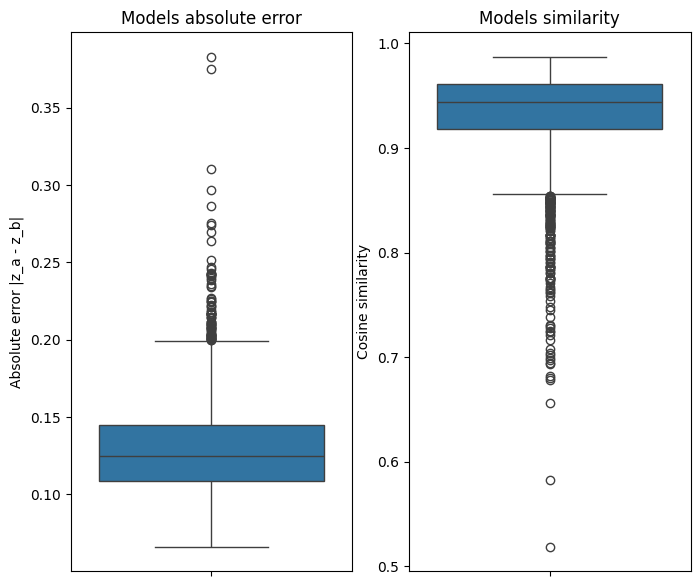

In [22]:
_, axes = plt.subplots(nrows=1, ncols=2, figsize=(8, 7))

sns.boxplot(y=mse, legend=False, ax=axes[0])
axes[0].set_ylabel("Absolute error |z_a - z_b|")
axes[0].set_title("Models absolute error")

sns.boxplot(y=sim, legend=False, ax=axes[1])
axes[1].set_ylabel("Cosine similarity")
axes[1].set_title("Models similarity")

plt.show()